<a href="https://colab.research.google.com/github/Paxlawa/Labu/blob/main/%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


In [7]:

dates = pd.date_range(start="2022-01-01", end="2025-12-31", freq="D")
np.random.seed(42)

trend = np.linspace(100, 200, len(dates))
weekly = 15 * np.sin(2 * np.pi * np.arange(len(dates)) / 7)
yearly = 20 * np.sin(2 * np.pi * np.arange(len(dates)) / 365.25)
weekend = np.where(dates.dayofweek >= 5, -10, 0)
noise = np.random.normal(0, 8, len(dates))

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({"date": dates, "sales": sales})

df.loc[[120, 450, 900], "sales"] = np.nan
df.loc[[300, 700, 1100], "sales"] *= 2

df.head()


,date,sales
0,2022-01-01,93.973713
1,2022-01-02,101.033882
2,2022-01-03,120.630375
3,2022-01-04,119.929662
4,2022-01-05,93.267598


In [8]:

if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").drop_duplicates("date")
    df = df.set_index("date")

df.index = pd.to_datetime(df.index)
df = df.sort_index()
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")
df = df[~df.index.duplicated(keep="first")]
df = df.asfreq("D")
df["sales"] = df["sales"].interpolate(method="time")


In [9]:

print("Кількість спостережень:", len(df))
print("Початкова дата:", df.index.min())
print("Кінцева дата:", df.index.max())
print("\nСтатистика:")
print(df["sales"].describe())
print("\nПропуски:", df["sales"].isna().sum())
print("Частота:", pd.infer_freq(df.index))
print("Дублікати дат:", df.index.duplicated().sum())


Кількість спостережень: 1461
Початкова дата: 2022-01-01 00:00:00
Кінцева дата: 2025-12-31 00:00:00

Статистика:
count    1461.000000
mean      147.771984
std        33.030299
min        69.449378
25%       121.940170
50%       147.762054
75%       173.036912
max       373.029845
Name: sales, dtype: float64

Пропуски: 0
Частота: D
Дублікати дат: 0


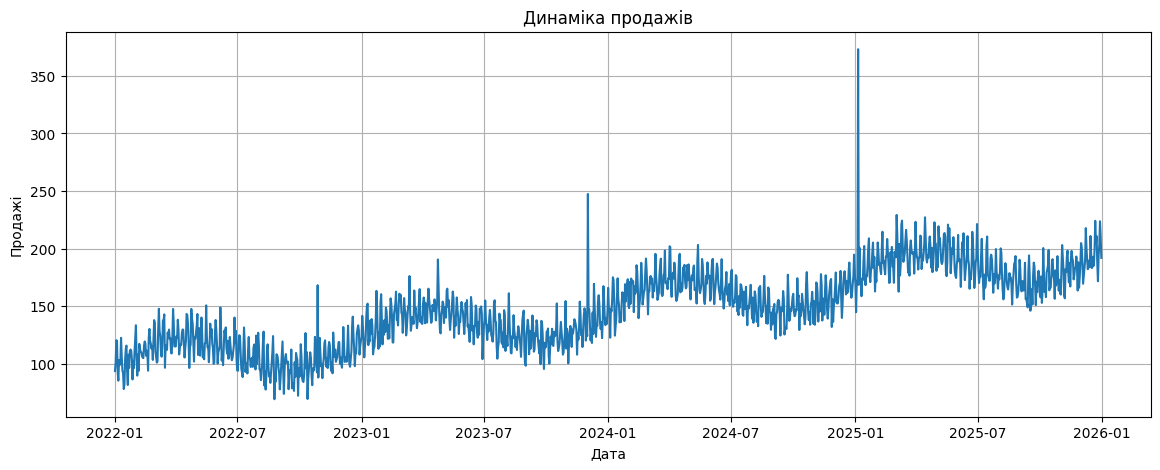

In [10]:

plt.figure(figsize=(14, 5))
plt.plot(df.index, df["sales"])
plt.title("Динаміка продажів")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.grid(True)
plt.show()


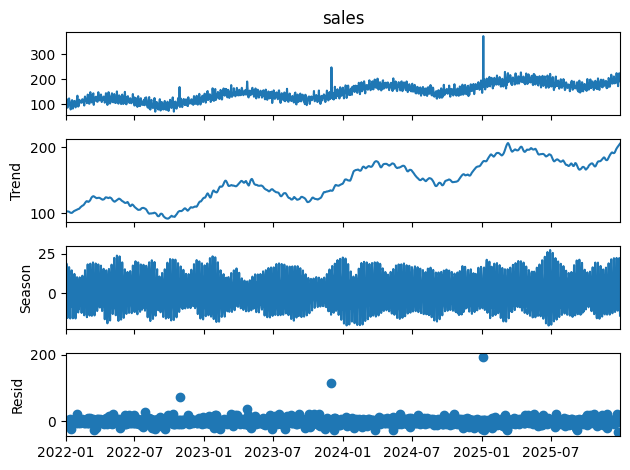

In [11]:

stl = STL(df["sales"], period=7, robust=True)
result = stl.fit()

result.plot()
plt.show()


In [12]:

test_size = 60

train = df["sales"].iloc[:-test_size]
test = df["sales"].iloc[-test_size:]

print("Навчальних спостережень:", len(train))
print("Тестових спостережень:", len(test))
print("Початок тестового періоду:", test.index.min())
print("Кінець тестового періоду:", test.index.max())


Навчальних спостережень: 1401
Тестових спостережень: 60
Початок тестового періоду: 2025-11-02 00:00:00
Кінець тестового періоду: 2025-12-31 00:00:00


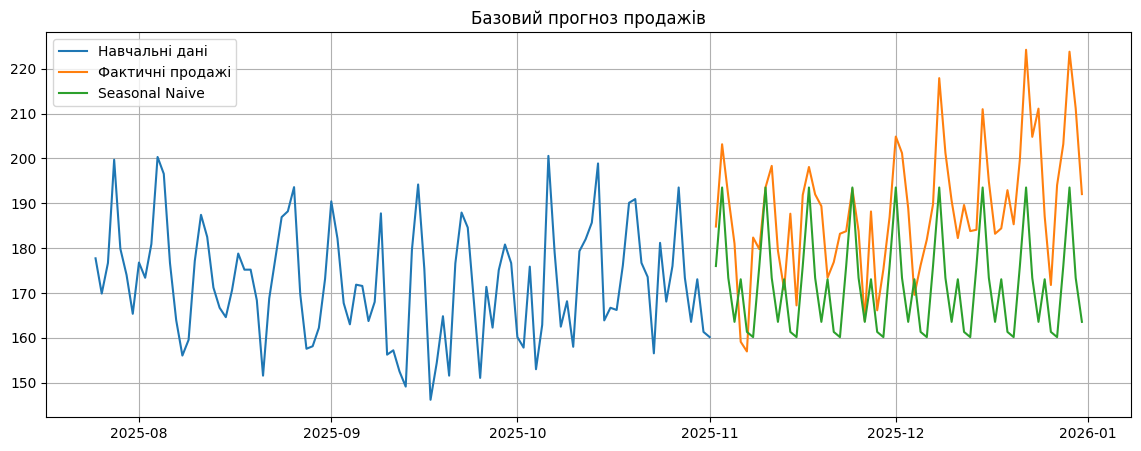

In [13]:

seasonal_period = 7

baseline_forecast = np.resize(
    train.iloc[-seasonal_period:].values,
    len(test)
)

baseline_forecast = pd.Series(
    baseline_forecast,
    index=test.index
)

plt.figure(figsize=(14, 5))
plt.plot(train.index[-100:], train.iloc[-100:], label="Навчальні дані")
plt.plot(test.index, test, label="Фактичні продажі")
plt.plot(test.index, baseline_forecast, label="Seasonal Naive")
plt.title("Базовий прогноз продажів")
plt.legend()
plt.grid(True)
plt.show()


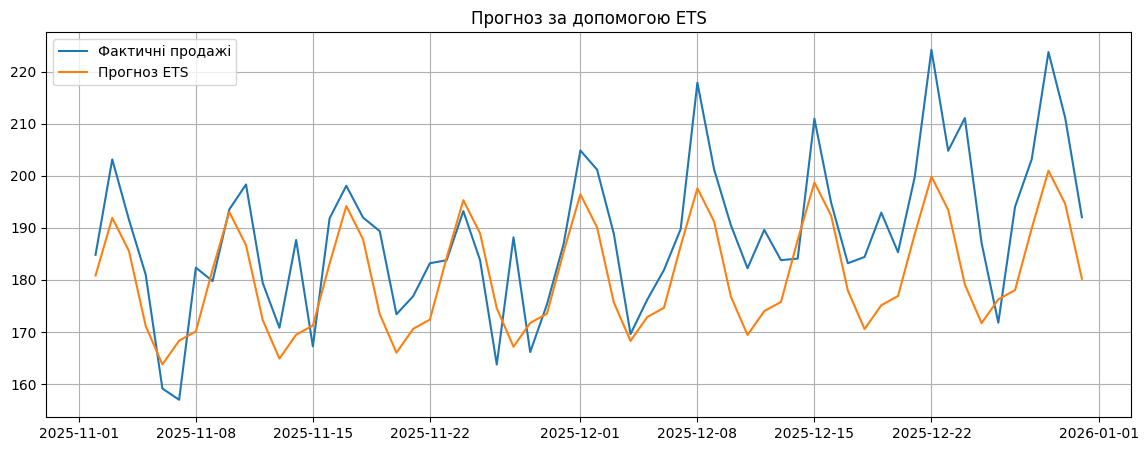

In [14]:

ets_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7
)

ets_fit = ets_model.fit()
ets_forecast = ets_fit.forecast(len(test))

ets_forecast.index = test.index

plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні продажі")
plt.plot(test.index, ets_forecast, label="Прогноз ETS")
plt.title("Прогноз за допомогою ETS")
plt.legend()
plt.grid(True)
plt.show()


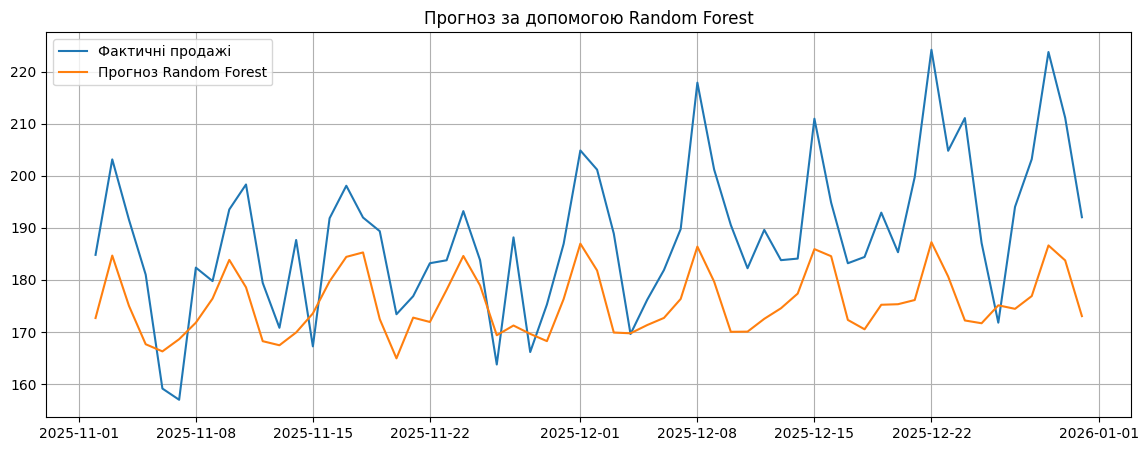

In [15]:

def create_features(series):
    data = pd.DataFrame(index=series.index)
    data["lag_1"] = series.shift(1)
    data["lag_2"] = series.shift(2)
    data["lag_7"] = series.shift(7)
    data["lag_14"] = series.shift(14)
    data["lag_28"] = series.shift(28)
    data["day_of_week"] = series.index.dayofweek
    data["month"] = series.index.month
    data["day_of_year"] = series.index.dayofyear
    return data

features = create_features(train)
target = train.copy()

valid = features.notna().all(axis=1)
X_train = features.loc[valid]
y_train = target.loc[valid]

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

history = train.copy()
rf_predictions = []

for date in test.index:
    row = pd.DataFrame(index=[date])
    row["lag_1"] = history.iloc[-1]
    row["lag_2"] = history.iloc[-2]
    row["lag_7"] = history.iloc[-7]
    row["lag_14"] = history.iloc[-14]
    row["lag_28"] = history.iloc[-28]
    row["day_of_week"] = date.dayofweek
    row["month"] = date.month
    row["day_of_year"] = date.dayofyear

    prediction = rf_model.predict(row)[0]
    rf_predictions.append(prediction)

    history.loc[date] = prediction

rf_forecast = pd.Series(
    rf_predictions,
    index=test.index
)

plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні продажі")
plt.plot(test.index, rf_forecast, label="Прогноз Random Forest")
plt.title("Прогноз за допомогою Random Forest")
plt.legend()
plt.grid(True)
plt.show()


In [16]:

def calculate_metrics(actual, predicted, history):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    denominator = np.abs(actual) + np.abs(predicted)
    smape = np.mean(
        200 * np.abs(actual - predicted) /
        np.where(denominator == 0, 1, denominator)
    )

    seasonal_errors = np.abs(
        history.iloc[7:].values - history.iloc[:-7].values
    )

    scale = seasonal_errors.mean()

    mase = mae / scale if scale != 0 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE (%)": smape,
        "MASE": mase
    }


In [17]:

results = pd.DataFrame({
    "Seasonal Naive": calculate_metrics(
        test, baseline_forecast, train
    ),
    "ETS": calculate_metrics(
        test, ets_forecast, train
    ),
    "Random Forest": calculate_metrics(
        test, rf_forecast, train
    )
}).T

print(results.round(3))


                   MAE    RMSE  sMAPE (%)   MASE
Seasonal Naive  17.531  20.421      9.659  1.825
ETS              9.757  11.711      5.228  1.016
Random Forest   14.326  16.738      7.702  1.491


In [18]:

best_model_name = results["MAE"].idxmin()

forecasts = {
    "Seasonal Naive": baseline_forecast,
    "ETS": ets_forecast,
    "Random Forest": rf_forecast
}

best_forecast = forecasts[best_model_name]

baseline_mae = results.loc["Seasonal Naive", "MAE"]
best_mae = results.loc[best_model_name, "MAE"]

if baseline_mae != 0:
    improvement = (baseline_mae - best_mae) / baseline_mae * 100
else:
    improvement = np.nan

print("Найкраща модель:", best_model_name)
print("MAE базової моделі:", round(baseline_mae, 3))
print("MAE найкращої моделі:", round(best_mae, 3))
print("Покращення відносно базової моделі:", round(improvement, 2), "%")


Найкраща модель: ETS
MAE базової моделі: 17.531
MAE найкращої моделі: 9.757
Покращення відносно базової моделі: 44.35 %


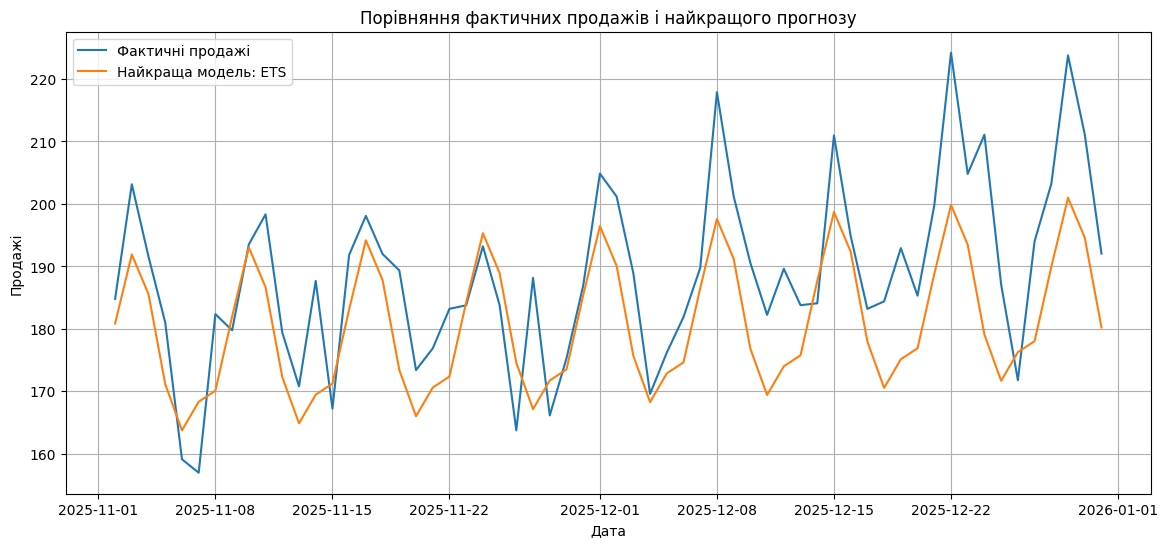

In [19]:

plt.figure(figsize=(14, 6))
plt.plot(test.index, test, label="Фактичні продажі")
plt.plot(test.index, best_forecast, label=f"Найкраща модель: {best_model_name}")
plt.title("Порівняння фактичних продажів і найкращого прогнозу")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.legend()
plt.grid(True)
plt.show()


In [20]:

print("ВИСНОВОК")
print()
print("Для прогнозування часових рядів було використано три моделі:")
print("Seasonal Naive, ETS і Random Forest.")
print()
print("Найкраща модель за показником MAE:", best_model_name)
print("Її MAE:", round(best_mae, 3))
print("MAE базової моделі:", round(baseline_mae, 3))

if best_model_name == "Seasonal Naive":
    print("Складніші моделі не покращили результат базового прогнозу.")
elif improvement > 0:
    print("Найкраща модель покращила результат базової моделі на",
          round(improvement, 2), "%.")
else:
    print("Найкраща модель не покращила результат базового прогнозу.")

print()
print("У даних присутні тренд, тижнева сезонність і випадкові коливання.")
print("Для аналізу сезонності використано метод STL.")
print("Точність оцінено на останніх 60 днях, які не використовувалися для навчання.")
print("Обмеження: дані синтетичні, а прогноз Random Forest будується послідовно.")
print("На реальних даних результати можуть відрізнятися.")


ВИСНОВОК

Для прогнозування часових рядів було використано три моделі:
Seasonal Naive, ETS і Random Forest.

Найкраща модель за показником MAE: ETS
Її MAE: 9.757
MAE базової моделі: 17.531
Найкраща модель покращила результат базової моделі на 44.35 %.

У даних присутні тренд, тижнева сезонність і випадкові коливання.
Для аналізу сезонності використано метод STL.
Точність оцінено на останніх 60 днях, які не використовувалися для навчання.
Обмеження: дані синтетичні, а прогноз Random Forest будується послідовно.
На реальних даних результати можуть відрізнятися.
